# Pipeline Proposal: Integration of CICIoT2023 & CICIoMT2024 (Justified)

**Diploma Thesis**: IoT/IoMT Network Intrusion Detection  
**Objective**: A documented pipeline proposal for dataset integration (integration strategy), with a **packet-level vs flow-level** decision and a **label harmonization** strategy.  
**Analysis basis**: The findings from notebooks 01–03 (especially the very high feature compatibility and the need for label unification).

---

## Table of Contents

1. [Goal & Assumptions](#1-goal--assumptions)
2. [Packet-level vs Flow-level: Decision & Justification](#2-packet-level-vs-flow-level-decision--justification)
3. [Proposed Integration Pipeline (Flow-level)](#3-proposed-integration-pipeline-flow-level)
4. [Feature Alignment Strategy (Schema + TTL rename)](#4-feature-alignment-strategy-schema--ttl-rename)
5. [Label Harmonization: 3-level Taxonomy (Binary → Category → Fine-grained)](#5-label-harmonization-3-level-taxonomy-binary--category--fine-grained)
6. [Train/Test Split Strategy & Evaluation](#6-traintest-split-strategy--evaluation)
7. [Data Quality Checks & Risks](#7-data-quality-checks--risks)
8. [Summary & Next Steps](#8-summary--next-steps)

## 1. Goal & Assumptions

### Goal
To produce **a single unified, ML-ready dataset** from CICIoT2023 and CICIoMT2024 with:
- **Unified feature schema** (feature alignment / type normalization)
- **Unified label taxonomy** (harmonized labels) at 3 levels
- **Realistic split & evaluation strategy** that respects the domain shift (generic IoT → IoMT)

### Assumptions / Constraints
- We work with **flow-level / window-based** CSVs (not directly with PCAPs), since both datasets already provide such features.
- The datasets were produced by the **same laboratory (CIC, UNB)** and use the **same feature extraction logic (DPKT, windows 10/100)** → high comparability.
- For CICIoMT2024, the labels are reliably derived from **the filename** (as in notebook 03).

## 2. Packet-level vs Flow-level: Decision & Justification

### Definitions (practical)
- **Packet-level integration**: integration at the packet level (PCAP), with potential re-extraction of features from payload/headers.
- **Flow-level (window-based) integration**: integration at the level of the already provided CSV rows, where each row is an aggregation over a window (10 or 100 packets).

### Comparison Table

| Criterion | Packet-level (PCAP) | Flow-level (CSV / windows) |
|---|---|---|
| **Data volume** | Very large (PCAPs hundreds of GB) | Significantly smaller, already ML-ready |
| **Reproducibility** | Requires exact re-extraction pipeline | High (same format/logic) |
| **Feature compatibility** | Requires feature set redesign | High: ~39 common features + 6 extra in IoMT2024 |
| **Label unification** | More difficult (label propagation) | Simple/deterministic (Label column or filename) |
| **Suitability for ML goal** | Complex/expensive | Direct for supervised IDS models |

### Decision
**Flow-level (CSV / window-based) integration is proposed**.

#### Justification
- The two datasets have a **nearly isomorphic feature space** (in notebook 03: common core + 1 rename + 6 extra).
- The labels are already available/recoverable without heuristics on the packet stream.
- The integration is done **quickly, with low computational cost**, and is suitable for the main deliverable (integrated ML-ready dataset).

> **Note**: Packet-level integration remains a possible future extension (e.g. for deep packet inspection), but is not necessary at this stage.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')

# ── Paths (same convention as notebooks 01–03) ──
CICIOT2023_DIR = Path('../data/raw/CICIoT2023')
CICIOMT2024_DIR = Path('../data/raw/CICIoMT2024')
CICIOMT2024_TRAIN = CICIOMT2024_DIR / 'train'
CICIOMT2024_TEST = CICIOMT2024_DIR / 'test'

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams.update({
    'figure.figsize': (12, 5),
    'figure.dpi': 110,
    'font.size': 11,
})

iot2023_files = sorted(CICIOT2023_DIR.glob('Merged*.csv'))
iomt2024_train_files = sorted(CICIOMT2024_TRAIN.glob('*.csv'))
iomt2024_test_files = sorted(CICIOMT2024_TEST.glob('*.csv'))
iomt2024_all_files = [f for f in (iomt2024_train_files + iomt2024_test_files) if f.name != '.gitkeep']

print('Configuration loaded successfully.')
print(f'CICIoT2023 directory:  {CICIOT2023_DIR} (exists: {CICIOT2023_DIR.exists()})')
print(f'CICIoMT2024 directory: {CICIOMT2024_DIR} (exists: {CICIOMT2024_DIR.exists()})')
print(f'  Train: {CICIOMT2024_TRAIN} (exists: {CICIOMT2024_TRAIN.exists()})')
print(f'  Test:  {CICIOMT2024_TEST} (exists: {CICIOMT2024_TEST.exists()})')
print(f'\nCICIoT2023 CSV files:  {len(iot2023_files)}')
print(f'CICIoMT2024 CSV files: {len(iomt2024_train_files)} train + {len(iomt2024_test_files)} test = {len(iomt2024_all_files)}')

assert len(iot2023_files) > 0, 'No CICIoT2023 CSVs found (Merged*.csv)'
assert len(iomt2024_all_files) > 0, 'No CICIoMT2024 CSVs found (train/test/*.csv)'

Configuration loaded successfully.
CICIoT2023 directory:  ../data/raw/CICIoT2023 (exists: True)
CICIoMT2024 directory: ../data/raw/CICIoMT2024 (exists: True)
  Train: ../data/raw/CICIoMT2024/train (exists: True)
  Test:  ../data/raw/CICIoMT2024/test (exists: True)

CICIoT2023 CSV files:  63
CICIoMT2024 CSV files: 51 train + 21 test = 72


In [2]:
# ══════════════════════════════════════════════════════════════════════
# 4a. Feature schema inspection (headers only)
# ══════════════════════════════════════════════════════════════════════

iot2023_cols = list(pd.read_csv(iot2023_files[0], nrows=0).columns)
iomt2024_cols = list(pd.read_csv(iomt2024_all_files[0], nrows=0).columns)

set_2023 = set(iot2023_cols)
set_2024 = set(iomt2024_cols)

# Label columns (known)
LABEL_COL_2023 = 'Label' if 'Label' in set_2023 else None

# Known rename equivalence (from notebook 03 findings)
RENAMED_EQUIV = {
    'Duration': 'Time_To_Live',
}

common_cols = sorted((set_2023 & set_2024))
only_2023 = sorted(set_2023 - set_2024)
only_2024 = sorted(set_2024 - set_2023)

print(f'CICIoT2023 columns:  {len(iot2023_cols)}')
print(f'CICIoMT2024 columns: {len(iomt2024_cols)}')
print(f'Common columns:      {len(common_cols)}')
print(f'Only CICIoT2023:     {len(only_2023)}')
print(f'Only CICIoMT2024:    {len(only_2024)}')

ttl_equiv = ('Time_To_Live' in set_2023) and ('Duration' in set_2024)
print(f"\nTTL-equivalence detected (Time_To_Live ↔ Duration): {ttl_equiv}")

# Canonical decision for schema alignment
CANON_TTL = 'Time_To_Live'  # canonical column name

# Common mappable feature set (treat TTL as equivalent)
features_2023 = [c for c in iot2023_cols if c != LABEL_COL_2023]
features_2024 = iomt2024_cols  # IoMT labels are filename-derived

mappable_2023 = set(features_2023)
mappable_2024 = set(features_2024)
if ttl_equiv:
    mappable_2024 = (mappable_2024 - {'Duration'}) | {CANON_TTL}

common_mappable = sorted(mappable_2023 & mappable_2024)
print(f"\nMappable common features (after TTL rename): {len(common_mappable)}")
print('First 15 common mappable:', common_mappable[:15])

CICIoT2023 columns:  40
CICIoMT2024 columns: 45
Common columns:      38
Only CICIoT2023:     2
Only CICIoMT2024:    7

TTL-equivalence detected (Time_To_Live ↔ Duration): True

Mappable common features (after TTL rename): 39
First 15 common mappable: ['ARP', 'AVG', 'DHCP', 'DNS', 'HTTP', 'HTTPS', 'Header_Length', 'IAT', 'ICMP', 'IGMP', 'IPv', 'IRC', 'LLC', 'Max', 'Min']


## 3. Proposed Integration Pipeline (Flow-level)

### High-level flow

### Steps (with minimal, targeted transformations)

1. **Ingestion**: reading CSVs with chunking / sampling where needed.
2. **Feature schema mapping**: defining the canonical schema (common feature core + policy for extras).
3. **Column rename**: unifying the TTL field: `Duration` → `Time_To_Live`.
4. **Type normalization**: coercion to numeric, handling of `inf`, `-inf`, `NaN`.
5. **Label harmonization**: mapping to 3 levels: `binary`, `category`, `unified_fine`.
6. **Validation**: schema checks, missingness, ranges, duplicates, leakage-sensitive fields.
7. **Split strategy**: designing a split that measures both within-domain and cross-domain generalization.
8. **Output**: unified dataset (e.g. parquet) + metadata (schema, label maps).

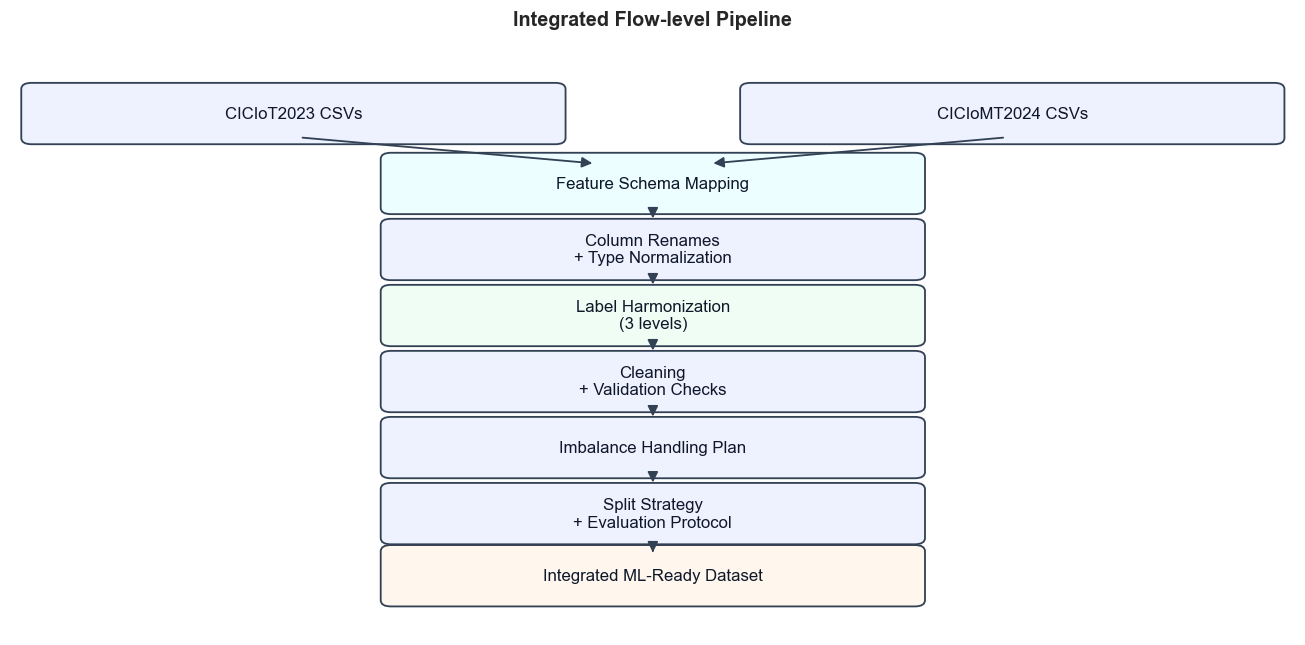

In [3]:
# ══════════════════════════════════════════════════════════════════════
# 3a. Pipeline Diagram (offline render)
# To render correctly inside Cursor/Jupyter without Mermaid/JS/Internet.
# ══════════════════════════════════════════════════════════════════════

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch


def add_box(ax, x, y, text, w=4.2, h=0.75, fc='#eef2ff', ec='#334155'):
    """Add a rounded box centered at (x,y). Returns box bounds."""
    left = x - w / 2
    bottom = y - h / 2
    patch = FancyBboxPatch(
        (left, bottom),
        w,
        h,
        boxstyle='round,pad=0.02,rounding_size=0.08',
        linewidth=1.2,
        edgecolor=ec,
        facecolor=fc,
    )
    ax.add_patch(patch)
    ax.text(x, y, text, ha='center', va='center', fontsize=11, color='#0f172a', wrap=True)
    return (left, bottom, w, h)


def arrow(ax, x1, y1, x2, y2, color='#334155'):
    ax.add_patch(
        FancyArrowPatch(
            (x1, y1),
            (x2, y2),
            arrowstyle='-|>',
            mutation_scale=14,
            linewidth=1.2,
            color=color,
            shrinkA=6,
            shrinkB=6,
        )
    )


fig, ax = plt.subplots(figsize=(12, 6))
ax.set_xlim(0, 10)
# We need a bit of space below so the last box is not cut off
ax.set_ylim(-1.4, 6.2)
ax.axis('off')

# Nodes (layout)
A = add_box(ax, 2.2, 5.3, 'CICIoT2023 CSVs')
B = add_box(ax, 7.8, 5.3, 'CICIoMT2024 CSVs')
C = add_box(ax, 5.0, 4.4, 'Feature Schema Mapping', fc='#ecfeff')
D = add_box(ax, 5.0, 3.55, 'Column Renames\n+ Type Normalization')
E = add_box(ax, 5.0, 2.70, 'Label Harmonization\n(3 levels)', fc='#f0fdf4')
F = add_box(ax, 5.0, 1.85, 'Cleaning\n+ Validation Checks')
G = add_box(ax, 5.0, 1.00, 'Imbalance Handling Plan')
H = add_box(ax, 5.0, 0.15, 'Split Strategy\n+ Evaluation Protocol')
I = add_box(ax, 5.0, -0.65, 'Integrated ML-Ready Dataset', fc='#fff7ed')

# Arrow connections
arrow(ax, 2.2, 5.0, 4.6, 4.65)   # A -> C
arrow(ax, 7.8, 5.0, 5.4, 4.65)   # B -> C

arrow(ax, 5.0, 4.05, 5.0, 3.95)  # C -> D
arrow(ax, 5.0, 3.20, 5.0, 3.10)  # D -> E
arrow(ax, 5.0, 2.35, 5.0, 2.25)  # E -> F
arrow(ax, 5.0, 1.50, 5.0, 1.40)  # F -> G
arrow(ax, 5.0, 0.65, 5.0, 0.55)  # G -> H
arrow(ax, 5.0, -0.20, 5.0, -0.35) # H -> I

ax.set_title('Integrated Flow-level Pipeline', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

In [4]:
# ══════════════════════════════════════════════════════════════════════
# 4c. Canonical schema proposal (common core + extras)
# ══════════════════════════════════════════════════════════════════════

# Features present in each dataset (excluding labels)
features_2023_set = set(features_2023)
features_2024_set = set(features_2024)

# Apply TTL rename equivalence for schema accounting
features_2024_aligned = (features_2024_set - {'Duration'}) | ({'Time_To_Live'} if 'Duration' in features_2024_set else set())

common_core = sorted(features_2023_set & features_2024_aligned)
extras_iomt = sorted(features_2024_aligned - features_2023_set)
extras_iot = sorted(features_2023_set - features_2024_aligned)

# Two schema variants
canonical_features_base = common_core  # recommended default (strictly-common)
canonical_features_extended = sorted(set(common_core) | set(extras_iomt) | set(extras_iot))

print('Canonical schema summary')
print('========================')
print(f'Common core features:  {len(common_core)}')
print(f'Extras only in IoMT2024 (after TTL rename): {len(extras_iomt)}')
print(f'Extras only in IoT2023: {len(extras_iot)}')

print('\nIoMT2024-only extras (for EXTENDED variant):')
print(extras_iomt)

print('\nIoT2023-only extras:')
print(extras_iot)

print('\nRecommendation')
print('==============')
print(f'BASE integrated schema (strictly-common): {len(canonical_features_base)} features')
print(f'EXTENDED schema (union, requires missingness policy): {len(canonical_features_extended)} features')

Canonical schema summary
Common core features:  39
Extras only in IoMT2024 (after TTL rename): 6
Extras only in IoT2023: 0

IoMT2024-only extras (for EXTENDED variant):
['Covariance', 'Drate', 'Magnitue', 'Radius', 'Srate', 'Weight']

IoT2023-only extras:
[]

Recommendation
BASE integrated schema (strictly-common): 39 features
EXTENDED schema (union, requires missingness policy): 45 features


## 4. Feature Alignment Strategy (Schema + TTL rename)

### Canonical Schema (proposal)
- **We keep the common core** (common mappable features).
- **Choice for extra features of CICIoMT2024**: 
  - either we keep them and fill with `NaN` for CICIoT2023 (so as not to lose information in the IoMT domain),
  - or we remove them for strictly-common models.

**Best choice (recommendation for the “main” integrated dataset)**:  
✅ **Strictly-common schema (intersection)**, i.e. **39 common features + canonical TTL**, and *not* the IoMT-only extras in the base merge.

**Why?** If we keep the 6 IoMT-only features in the unified dataset, then for all CICIoT2023 samples they will be **systematically NaN** (missingness by-domain). This:
- requires **imputation or missingness-aware models** to work properly,
- can act as a “shortcut” that encodes **which dataset a sample comes from** (IoT vs IoMT), blurring the **cross-domain generalization**.

**Proposed compromise**: we also keep an **extended** version (union schema) *only* for IoMT-focused experiments, with an explicit missingness policy (e.g. indicator + imputation) and separate evaluation.

### The critical rename
- In CICIoT2023, `Time_To_Live` appears.
- In CICIoMT2024, `Duration` appears, but in notebook 03 it is documented that it functionally corresponds to TTL.
- To avoid duplicate columns, we apply the **rule**: `Duration` → `Time_To_Live`.

### Note on labels in CICIoMT2024
The labels are not based on a column, but on **the filename** → we keep them as `orig_label` during reading.

In [5]:
# ══════════════════════════════════════════════════════════════════════
# 4b. Helpers: label extraction & lightweight unique-label scan
# ══════════════════════════════════════════════════════════════════════

def extract_iomt_label(filename: str) -> str:
    """Extract attack label from CICIoMT2024 filename.

    Examples:
        Benign_train.pcap.csv                -> Benign
        TCP_IP-DDoS-ICMP3_train.pcap.csv     -> TCP_IP-DDoS-ICMP
        MQTT-DoS-Connect_Flood_test.pcap.csv -> MQTT-DoS-Connect_Flood
    """
    name = re.sub(r'_(train|test)\.pcap\.csv$', '', filename)
    name = re.sub(r'\d+$', '', name)
    return name


def scan_unique_labels_iot2023(files, label_col='Label', chunksize=1_000_000, max_files=None):
    """Memory-friendly scan for unique labels in CICIoT2023.
    Set max_files for a quick scan (sampling)."""
    uniq = set()
    for i, f in enumerate(files):
        if (max_files is not None) and (i >= max_files):
            break
        for chunk in pd.read_csv(f, usecols=[label_col], chunksize=chunksize):
            uniq.update(chunk[label_col].dropna().unique().tolist())
    return sorted(uniq)


def unique_labels_iomt2024_from_filenames(files):
    return sorted({extract_iomt_label(f.name) for f in files if f.name != '.gitkeep'})


iomt_unique = unique_labels_iomt2024_from_filenames(iomt2024_all_files)
print(f'CICIoMT2024 unique labels (from filenames): {len(iomt_unique)}')
print('First 10:', iomt_unique[:10])

# For CICIoT2023, by default we do a quick scan (e.g. first 3 files) to avoid an expensive full pass.
iot_unique_quick = scan_unique_labels_iot2023(iot2023_files, max_files=3)
print(f'\nCICIoT2023 unique labels (quick scan, first 3 files): {len(iot_unique_quick)}')
print('Quick-scan labels:', iot_unique_quick)

CICIoMT2024 unique labels (from filenames): 19
First 10: ['ARP_Spoofing', 'Benign', 'MQTT-DDoS-Connect_Flood', 'MQTT-DDoS-Publish_Flood', 'MQTT-DoS-Connect_Flood', 'MQTT-DoS-Publish_Flood', 'MQTT-Malformed_Data', 'Recon-OS_Scan', 'Recon-Ping_Sweep', 'Recon-Port_Scan']



CICIoT2023 unique labels (quick scan, first 3 files): 34
Quick-scan labels: ['BACKDOOR_MALWARE', 'BENIGN', 'BROWSERHIJACKING', 'COMMANDINJECTION', 'DDOS-ACK_FRAGMENTATION', 'DDOS-HTTP_FLOOD', 'DDOS-ICMP_FLOOD', 'DDOS-ICMP_FRAGMENTATION', 'DDOS-PSHACK_FLOOD', 'DDOS-RSTFINFLOOD', 'DDOS-SLOWLORIS', 'DDOS-SYNONYMOUSIP_FLOOD', 'DDOS-SYN_FLOOD', 'DDOS-TCP_FLOOD', 'DDOS-UDP_FLOOD', 'DDOS-UDP_FRAGMENTATION', 'DICTIONARYBRUTEFORCE', 'DNS_SPOOFING', 'DOS-HTTP_FLOOD', 'DOS-SYN_FLOOD', 'DOS-TCP_FLOOD', 'DOS-UDP_FLOOD', 'MIRAI-GREETH_FLOOD', 'MIRAI-GREIP_FLOOD', 'MIRAI-UDPPLAIN', 'MITM-ARPSPOOFING', 'RECON-HOSTDISCOVERY', 'RECON-OSSCAN', 'RECON-PINGSWEEP', 'RECON-PORTSCAN', 'SQLINJECTION', 'UPLOADING_ATTACK', 'VULNERABILITYSCAN', 'XSS']


## 5. Label Harmonization: 3-level Taxonomy (Binary → Category → Fine-grained)

### Why 3 levels?
- **Binary**: simplified detection (Benign vs Attack), useful as a baseline.
- **Category**: stable, broad categories (DDoS, DoS, Recon, Spoofing, MQTT, Mirai, Web-based, Brute Force).
- **Fine-grained (unified)**: we keep the information about the specific attack type, but with **unified naming** so we can compare attacks of the "same meaning" across datasets.

### Rules
- For CICIoT2023: `orig_label` = value of the `Label` column.
- For CICIoMT2024: `orig_label` = label from filename.
- We produce three new fields: `y_binary`, `y_category`, `y_unified`.

In [6]:
# ══════════════════════════════════════════════════════════════════════
# 5a. Unified label taxonomy (3 levels)
# (same mapping as notebook 03, for consistency across the project)
# ══════════════════════════════════════════════════════════════════════

unified_taxonomy = {
    # ── CICIoT2023 labels ──
    'BENIGN':                   {'binary': 'Benign',  'category': 'Benign',          'unified': 'Benign'},
    'DDOS-SYN_FLOOD':           {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-SYN_Flood'},
    'DDOS-TCP_FLOOD':           {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-TCP_Flood'},
    'DDOS-UDP_FLOOD':           {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-UDP_Flood'},
    'DDOS-ICMP_FLOOD':          {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-ICMP_Flood'},
    'DDOS-ACK_FRAGMENTATION':   {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-ACK_Fragmentation'},
    'DDOS-HTTP_FLOOD':          {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-HTTP_Flood'},
    'DDOS-ICMP_FRAGMENTATION':  {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-ICMP_Fragmentation'},
    'DDOS-PSHACK_FLOOD':        {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-PSHACK_Flood'},
    'DDOS-RSTFINFLOOD':         {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-RSTFIN_Flood'},
    'DDOS-SLOWLORIS':           {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-Slowloris'},
    'DDOS-SYNONYMOUSIP_FLOOD':  {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-SynonymousIP_Flood'},
    'DDOS-UDP_FRAGMENTATION':   {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-UDP_Fragmentation'},
    'DOS-SYN_FLOOD':            {'binary': 'Attack',  'category': 'DoS',             'unified': 'DoS-SYN_Flood'},
    'DOS-TCP_FLOOD':            {'binary': 'Attack',  'category': 'DoS',             'unified': 'DoS-TCP_Flood'},
    'DOS-UDP_FLOOD':            {'binary': 'Attack',  'category': 'DoS',             'unified': 'DoS-UDP_Flood'},
    'DOS-HTTP_FLOOD':           {'binary': 'Attack',  'category': 'DoS',             'unified': 'DoS-HTTP_Flood'},
    'MIRAI-GREETH_FLOOD':       {'binary': 'Attack',  'category': 'Mirai',           'unified': 'Mirai-GREETH_Flood'},
    'MIRAI-GREIP_FLOOD':        {'binary': 'Attack',  'category': 'Mirai',           'unified': 'Mirai-GREIP_Flood'},
    'MIRAI-UDPPLAIN':           {'binary': 'Attack',  'category': 'Mirai',           'unified': 'Mirai-UDPPlain'},
    'RECON-HOSTDISCOVERY':      {'binary': 'Attack',  'category': 'Reconnaissance',  'unified': 'Recon-Host_Discovery'},
    'RECON-OSSCAN':             {'binary': 'Attack',  'category': 'Reconnaissance',  'unified': 'Recon-OS_Scan'},
    'RECON-PINGSWEEP':          {'binary': 'Attack',  'category': 'Reconnaissance',  'unified': 'Recon-Ping_Sweep'},
    'RECON-PORTSCAN':           {'binary': 'Attack',  'category': 'Reconnaissance',  'unified': 'Recon-Port_Scan'},
    'VULNERABILITYSCAN':        {'binary': 'Attack',  'category': 'Reconnaissance',  'unified': 'Recon-Vuln_Scan'},
    'MITM-ARPSPOOFING':         {'binary': 'Attack',  'category': 'Spoofing',         'unified': 'ARP_Spoofing'},
    'DNS_SPOOFING':             {'binary': 'Attack',  'category': 'Spoofing',         'unified': 'DNS_Spoofing'},
    'BROWSERHIJACKING':         {'binary': 'Attack',  'category': 'Web-based',        'unified': 'Web-BrowserHijacking'},
    'COMMANDINJECTION':         {'binary': 'Attack',  'category': 'Web-based',        'unified': 'Web-CommandInjection'},
    'SQLINJECTION':             {'binary': 'Attack',  'category': 'Web-based',        'unified': 'Web-SQLInjection'},
    'XSS':                      {'binary': 'Attack',  'category': 'Web-based',        'unified': 'Web-XSS'},
    'UPLOADING_ATTACK':         {'binary': 'Attack',  'category': 'Web-based',        'unified': 'Web-UploadingAttack'},
    'BACKDOOR_MALWARE':         {'binary': 'Attack',  'category': 'Web-based',        'unified': 'Web-BackdoorMalware'},
    'DICTIONARYBRUTEFORCE':     {'binary': 'Attack',  'category': 'Brute Force',      'unified': 'BruteForce-Dictionary'},

    # ── CICIoMT2024 labels ──
    'Benign':                      {'binary': 'Benign',  'category': 'Benign',          'unified': 'Benign'},
    'TCP_IP-DDoS-SYN':             {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-SYN_Flood'},
    'TCP_IP-DDoS-TCP':             {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-TCP_Flood'},
    'TCP_IP-DDoS-UDP':             {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-UDP_Flood'},
    'TCP_IP-DDoS-ICMP':            {'binary': 'Attack',  'category': 'DDoS',            'unified': 'DDoS-ICMP_Flood'},
    'TCP_IP-DoS-SYN':              {'binary': 'Attack',  'category': 'DoS',             'unified': 'DoS-SYN_Flood'},
    'TCP_IP-DoS-TCP':              {'binary': 'Attack',  'category': 'DoS',             'unified': 'DoS-TCP_Flood'},
    'TCP_IP-DoS-UDP':              {'binary': 'Attack',  'category': 'DoS',             'unified': 'DoS-UDP_Flood'},
    'TCP_IP-DoS-ICMP':             {'binary': 'Attack',  'category': 'DoS',             'unified': 'DoS-ICMP_Flood'},
    'MQTT-DDoS-Connect_Flood':     {'binary': 'Attack',  'category': 'MQTT',            'unified': 'MQTT-DDoS-Connect_Flood'},
    'MQTT-DDoS-Publish_Flood':     {'binary': 'Attack',  'category': 'MQTT',            'unified': 'MQTT-DDoS-Publish_Flood'},
    'MQTT-DoS-Connect_Flood':      {'binary': 'Attack',  'category': 'MQTT',            'unified': 'MQTT-DoS-Connect_Flood'},
    'MQTT-DoS-Publish_Flood':      {'binary': 'Attack',  'category': 'MQTT',            'unified': 'MQTT-DoS-Publish_Flood'},
    'MQTT-Malformed_Data':         {'binary': 'Attack',  'category': 'MQTT',            'unified': 'MQTT-Malformed_Data'},
    'Recon-OS_Scan':               {'binary': 'Attack',  'category': 'Reconnaissance',  'unified': 'Recon-OS_Scan'},
    'Recon-Ping_Sweep':            {'binary': 'Attack',  'category': 'Reconnaissance',  'unified': 'Recon-Ping_Sweep'},
    'Recon-Port_Scan':             {'binary': 'Attack',  'category': 'Reconnaissance',  'unified': 'Recon-Port_Scan'},
    'Recon-VulScan':               {'binary': 'Attack',  'category': 'Reconnaissance',  'unified': 'Recon-Vuln_Scan'},
    'ARP_Spoofing':                {'binary': 'Attack',  'category': 'Spoofing',         'unified': 'ARP_Spoofing'},
}


def map_label(orig_label: str):
    info = unified_taxonomy.get(orig_label)
    if info is None:
        return {'binary': 'Unknown', 'category': 'Unknown', 'unified': 'Unknown'}
    return info


# Display as a compact table
tax_df = (
    pd.DataFrame([
        {'orig_label': k, 'y_binary': v['binary'], 'y_category': v['category'], 'y_unified': v['unified']}
        for k, v in unified_taxonomy.items()
    ])
    .sort_values(['y_category', 'y_unified', 'orig_label'])
    .reset_index(drop=True)
)

print(f'Unified taxonomy size: {len(tax_df)} original-label keys')
tax_df.head(12)

Unified taxonomy size: 53 original-label keys


,orig_label,y_binary,y_category,y_unified
0,BENIGN,Benign,Benign,Benign
1,Benign,Benign,Benign,Benign
2,DICTIONARYBRUTEFORCE,Attack,Brute Force,BruteForce-Dictionary
3,DDOS-ACK_FRAGMENTATION,Attack,DDoS,DDoS-ACK_Fragmentation
4,DDOS-HTTP_FLOOD,Attack,DDoS,DDoS-HTTP_Flood
5,DDOS-ICMP_FLOOD,Attack,DDoS,DDoS-ICMP_Flood
6,TCP_IP-DDoS-ICMP,Attack,DDoS,DDoS-ICMP_Flood
7,DDOS-ICMP_FRAGMENTATION,Attack,DDoS,DDoS-ICMP_Fragmentation
8,DDOS-PSHACK_FLOOD,Attack,DDoS,DDoS-PSHACK_Flood
9,DDOS-RSTFINFLOOD,Attack,DDoS,DDoS-RSTFIN_Flood


In [7]:
# ══════════════════════════════════════════════════════════════════════
# 5b. Coverage check (taxonomy vs observed labels)
# ══════════════════════════════════════════════════════════════════════

RUN_FULL_IOT2023_LABEL_SCAN = False  # set True for full inventory of labels (will take time)

if RUN_FULL_IOT2023_LABEL_SCAN:
    iot_unique = scan_unique_labels_iot2023(iot2023_files, max_files=None)
else:
    # quick scan (first 3 files) is sufficient to confirm that the mapping covers the expected labels
    iot_unique = iot_unique_quick

iomt_unique = unique_labels_iomt2024_from_filenames(iomt2024_all_files)

missing_iot = sorted(set(iot_unique) - set(unified_taxonomy.keys()))
missing_iomt = sorted(set(iomt_unique) - set(unified_taxonomy.keys()))

print('Observed label keys (scan):')
print(f'  CICIoT2023 unique labels scanned:  {len(iot_unique)}')
print(f'  CICIoMT2024 unique labels (files): {len(iomt_unique)}')

print('\nMissing from taxonomy:')
print(f'  CICIoT2023 missing:  {len(missing_iot)}')
if missing_iot:
    print('   ', missing_iot)
print(f'  CICIoMT2024 missing: {len(missing_iomt)}')
if missing_iomt:
    print('   ', missing_iomt)

print('\nFine-grained overlap (based on taxonomy keys):')
iot_unified = {unified_taxonomy[l]['unified'] for l in iot_unique if l in unified_taxonomy}
iomt_unified = {unified_taxonomy[l]['unified'] for l in iomt_unique if l in unified_taxonomy}
print(f'  Shared unified labels: {len(iot_unified & iomt_unified)}')
print(f'  Only CICIoT2023:       {len(iot_unified - iomt_unified)}')
print(f'  Only CICIoMT2024:      {len(iomt_unified - iot_unified)}')

Observed label keys (scan):
  CICIoT2023 unique labels scanned:  34
  CICIoMT2024 unique labels (files): 19

Missing from taxonomy:
  CICIoT2023 missing:  0
  CICIoMT2024 missing: 0

Fine-grained overlap (based on taxonomy keys):
  Shared unified labels: 13
  Only CICIoT2023:       21
  Only CICIoMT2024:      6


In [8]:
# ══════════════════════════════════════════════════════════════════════
# 5c. Mini end-to-end demo (sample ingestion → harmonize → concat)
# (quick, to demonstrate the steps without heavy compute)
# ══════════════════════════════════════════════════════════════════════

N = 5000

# ── CICIoT2023 sample ──
df_iot = pd.read_csv(iot2023_files[0], nrows=N)
if 'Label' in df_iot.columns:
    df_iot['orig_label'] = df_iot['Label']
    df_iot = df_iot.drop(columns=['Label'])
else:
    df_iot['orig_label'] = 'Unknown'

df_iot['dataset'] = 'CICIoT2023'

# ── CICIoMT2024 sample ──
iomt_file = iomt2024_all_files[0]
df_iomt = pd.read_csv(iomt_file, nrows=N)
if 'Duration' in df_iomt.columns and 'Time_To_Live' not in df_iomt.columns:
    df_iomt = df_iomt.rename(columns={'Duration': 'Time_To_Live'})

df_iomt['orig_label'] = extract_iomt_label(iomt_file.name)
df_iomt['dataset'] = 'CICIoMT2024'

# ── Apply unified taxonomy ──
for _df in (df_iot, df_iomt):
    mapped = _df['orig_label'].map(map_label)
    _df['y_binary'] = mapped.map(lambda d: d['binary'])
    _df['y_category'] = mapped.map(lambda d: d['category'])
    _df['y_unified'] = mapped.map(lambda d: d['unified'])

# ── Align schemas (union) ──
all_cols = sorted(set(df_iot.columns) | set(df_iomt.columns))
df_iot_aligned = df_iot.reindex(columns=all_cols)
df_iomt_aligned = df_iomt.reindex(columns=all_cols)

integrated_sample = pd.concat([df_iot_aligned, df_iomt_aligned], ignore_index=True)

print('Integrated sample created')
print('========================')
print('CICIoT2023 sample shape:', df_iot.shape)
print('CICIoMT2024 sample shape:', df_iomt.shape)
print('Integrated sample shape:', integrated_sample.shape)

# Quick sanity checks
print('\nUnique y_category (sample):', sorted(integrated_sample['y_category'].dropna().unique().tolist()))

# Missingness per-dataset (high-level)
miss = (integrated_sample.isna().groupby(integrated_sample['dataset']).mean() * 100)
miss_summary = miss.mean(axis=1).rename('avg_missing_%')
miss_summary

Integrated sample created
CICIoT2023 sample shape: (5000, 44)
CICIoMT2024 sample shape: (5000, 50)
Integrated sample shape: (10000, 50)

Unique y_category (sample): ['Benign', 'DDoS', 'DoS', 'Mirai', 'Reconnaissance', 'Spoofing', 'Web-based']


dataset
CICIoMT2024     0.0
CICIoT2023     12.0
Name: avg_missing_%, dtype: float64

## 6. Train/Test Split Strategy & Evaluation

### Why "random mixing" is not sufficient
The integration introduces significant **domain shift** (generic IoT vs IoMT) and **scale imbalance** (CICIoT2023 >> CICIoMT2024). If we do a simple random split on the unified dataset, we risk measuring performance mainly on one domain.

### Proposed evaluation protocols

1. **Within-domain** (baseline):
   - Train/Test within each dataset (stratified with respect to `y_category` or `y_unified`).

2. **Cross-domain generalization** (critical for thesis):
   - Train on CICIoT2023 → Test on CICIoMT2024 (and vice versa where it makes sense).
   - Goal: to measure robust IDS behaviour when the environment changes.

3. **Hybrid** (integrated training):
   - Train on a mixture (with weighting/sampling) and Test on a held-out split per dataset.

### Imbalance handling (policy)
- We avoid letting CICIoT2023 "dominate" the training.
- Options: **subsampling**, **class weights**, or **balanced batch sampling** (per `y_category`).

## 7. Data Quality Checks & Risks

### Data quality checks (before the merge)
- **Schema check**: all expected columns exist (after renames).
- **Type coercion**: all numeric features coerced to numeric type (where needed `pd.to_numeric(errors='coerce')`).
- **Invalid values**: replacement of `inf/-inf` → `NaN`.
- **Missingness**: reporting and policy (impute / drop).
- **Constant / near-constant features**: potential removal.
- **Duplicates**: detection and policy.

### Key risks & mitigation
- **Distribution shift**: normalization/standardization *fit on train* (no leakage).
- **Label semantic mismatch**: use of unified taxonomy with explicit mapping.
- **Window-size heterogeneity (10 vs 100)**: either we keep an indicator feature (if it exists), or we accept it as inherent mixing and check the effects with ablation.
- **Extra features in IoMT2024**: policy (keep-with-NaN vs drop) per evaluation scenario.

## 8. Summary & Next Steps

### Decision summary
- **Integration at flow-level (CSV)** due to high feature compatibility, label availability and practical cost.
- **Feature alignment** with canonical schema and critical rename: `Duration` → `Time_To_Live`.
- **Label harmonization** with 3-level taxonomy for binary/category/fine-grained scenarios.

### Next steps (pipeline implementation)
- Writing a script/module that implements the pipeline (read → rename → type normalize → label map → validate → save).
- Production of `data/processed/` outputs (e.g. parquet) and accompanying metadata (schema + taxonomy export).
- Finalization of evaluation protocol and baseline models.